# Lista 4: Do texto ao número
**Caderno de atividades do Capítulo 4** | **A ginga dos números**, livro de exercícios | Professor Bruno Menezes | [repositório](https://github.com/brunoleomenezes/ginga-dos-numeros)

Nome: ______________________  Turma: ______________

O código de cada exercício já está nas células, com a saída visível, para você conferir. O ideal é **digitar** o código em um caderno seu, como pede a Lista em PDF, e usar este caderno para comparar. Execute as células **na ordem**: quase todas dependem das anteriores. Em caso de dúvida, use *Ambiente de execução > Reiniciar sessão e executar tudo*.

## Parte 1. Sete ferramentas novas de Python

### B1. Trabalhar com texto: minúsculas, palavras e junção

Todo o capítulo parte de frases. Três recursos do Python bastam: **.lower()** passa tudo para minúsculas, **.split()** corta a frase em uma lista de palavras e **" ".join(lista)** faz o caminho de volta.

In [1]:
# Guarda a frase (um texto entre aspas, chamado string) na variável frase
frase = "Preciso Emitir NOTA fiscal"

# .lower() passa tudo para minúsculas e .split() corta nos espaços, gerando uma lista
palavras = frase.lower().split()
# Mostra a lista; os colchetes indicam que é uma lista do Python
print(palavras)
# len conta os itens da lista; o print aceita vários valores separados por vírgula
print(len(palavras), "palavras")
# " ".join cola as palavras de volta usando um espaço como cola (o caminho inverso do split)
print(" ".join(palavras))
# A mesma junção, agora usando o hífen como cola
print("-".join(palavras))

['preciso', 'emitir', 'nota', 'fiscal']
4 palavras
preciso emitir nota fiscal
preciso-emitir-nota-fiscal


O split sem argumento corta nos espaços. O join une os itens de uma lista usando o texto antes do ponto como cola.

**SUA VEZ**

1. Troque a frase por "o cliente enviou a nota" e conte as palavras.
2. Use .split() com argumento, por exemplo "a-b-c".split("-"), e veja o resultado.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [2]:
# Espaço para os seus testes

### B2. Contar com Counter

Contar quantas vezes cada palavra aparece é a base de quase tudo no capítulo. O **Counter**, da biblioteca padrão **collections**, faz isso em uma linha e se comporta como um dicionário.

In [3]:
# Importa o Counter, um contador pronto da biblioteca padrão collections
from collections import Counter

# Corta a frase em palavras; o .split() pode ser usado direto sobre o texto entre aspas
palavras = "o cliente enviou o documento o cliente pagou".split()
# Counter conta quantas vezes cada palavra aparece (é um dicionário palavra: contagem)
contagem = Counter(palavras)

# Mostra todas as contagens, da mais frequente para a menos frequente
print(contagem)
# Consulta como num dicionário, pela chave; "imposto" não aparece e devolve 0 em vez de erro
print(contagem["o"], contagem["cliente"], contagem["imposto"])
# most_common(2) devolve os 2 pares (palavra, contagem) mais frequentes
print(contagem.most_common(2))

Counter({'o': 3, 'cliente': 2, 'enviou': 1, 'documento': 1, 'pagou': 1})
3 2 0
[('o', 3), ('cliente', 2)]


Uma palavra que não apareceu tem contagem zero, sem dar erro. O most_common devolve os itens mais frequentes, do maior para o menor.

**SUA VEZ**

1. Conte as letras da palavra "pagamento" usando Counter("pagamento").
2. Descubra qual palavra é a mais frequente em uma frase de sua escolha.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [4]:
# Espaço para os seus testes

### B3. Pares de vizinhos com zip

Um modelo de bigramas olha cada palavra e a seguinte. Para gerar todos os pares de vizinhos, costuramos a lista com ela mesma deslocada uma posição: **zip(lista, lista[1:])**.

In [5]:
# Lista de tokens de uma frase; <s> marca o início e </s> marca o fim
t = ["<s>", "o", "cliente", "enviou", "</s>"]

# Laço for: zip costura a lista com sua fatia t[1:] (sem o 1º item), formando pares de vizinhos
for a, b in zip(t, t[1:]):
    # Mostra cada par (palavra, próxima palavra), que é o que o modelo de bigramas conta
    print(a, "->", b)

# list(...) transforma os pares do zip em uma lista guardada, para podermos contá-los
pares = list(zip(t, t[1:]))
# Cinco itens geram quatro pares de vizinhos
print(len(pares), "pares")

<s> -> o
o -> cliente
cliente -> enviou
enviou -> </s>
4 pares


Uma lista de cinco itens tem quatro pares de vizinhos. A notação lista[1:] é uma fatia: a lista sem o primeiro item.

**SUA VEZ**

1. Gere os pares de vizinhos da frase "a contadora revisou a nota" (sem os marcadores).
2. Gere os trios de vizinhos usando zip(t, t[1:], t[2:]).

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [6]:
# Espaço para os seus testes

### B4. Tabelas de números com NumPy

A tabela de co-ocorrência tem uma linha e uma coluna para cada palavra. O NumPy cria uma tabela de zeros com **np.zeros**, permite somar 1 em uma célula com **M[i, j] += 1** e calcula somas por linha ou por coluna com **axis**.

In [7]:
# Importa o NumPy, a biblioteca de tabelas de números, com o apelido np
import numpy as np

# np.zeros((3, 3)) cria uma tabela (matriz) de 3 linhas e 3 colunas cheia de zeros
M = np.zeros((3, 3))
# M[0, 1] é a célula da linha 0, coluna 1 (conta-se a partir de 0); += 1 soma 1 ao valor
M[0, 1] += 1
# Soma mais 1 na mesma célula, que passa a valer 2 (como contar um par visto duas vezes)
M[0, 1] += 1
# Soma 1 na célula da linha 2, coluna 0
M[2, 0] += 1

# Mostra a tabela inteira
print(M)
# axis=1 soma andando pelas colunas: dá um total para cada linha
print("soma de cada linha:", M.sum(axis=1))
# axis=0 soma andando pelas linhas: dá um total para cada coluna
print("soma de cada coluna:", M.sum(axis=0))
# Sem axis, soma todas as células da tabela
print("total:", M.sum())

[[0. 2. 0.]
 [0. 0. 0.]
 [1. 0. 0.]]
soma de cada linha: [2. 0. 1.]
soma de cada coluna: [1. 2. 0.]
total: 3.0


O axis=1 soma ao longo das colunas (uma soma por linha), e o axis=0 soma ao longo das linhas (uma soma por coluna).

**SUA VEZ**

1. Acrescente 3 à célula da linha 1, coluna 2.
2. Calcule o maior valor da tabela com M.max().

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [8]:
# Espaço para os seus testes

### B5. Produto escalar, comprimento e cosseno

A semelhança do cosseno é o produto escalar de dois vetores dividido pelo produto dos comprimentos deles. Com NumPy, o produto escalar é **a @ b** e o comprimento é **np.linalg.norm(a)**.

In [9]:
# np.array transforma a lista em um vetor do NumPy, que permite contas com vetores
a = np.array([1, 1, 0])
# Segundo vetor; só a primeira posição é comum aos dois
b = np.array([1, 0, 1])

# O operador @ faz o produto escalar: multiplica posição a posição e soma tudo
produto = a @ b
# np.linalg.norm calcula o comprimento do vetor (raiz da soma dos quadrados)
comprimento_a = np.linalg.norm(a)
# Comprimento do vetor b
comprimento_b = np.linalg.norm(b)

# Mostra o produto escalar
print("produto escalar:", produto)
# round(x, 4) arredonda para 4 casas decimais
print("comprimentos:", round(comprimento_a, 4), round(comprimento_b, 4))
# Cosseno = produto escalar dividido pelo produto dos comprimentos (a semelhança do cosseno)
print("cosseno:", round(produto / (comprimento_a * comprimento_b), 4))
# Um vetor comparado com ele mesmo tem cosseno 1, o máximo de semelhança
print("cosseno de a com ele mesmo:", round(a @ a / (comprimento_a * comprimento_a), 4))

produto escalar: 1
comprimentos: 1.4142 1.4142
cosseno: 0.5
cosseno de a com ele mesmo: 1.0


Dois vetores iguais têm cosseno 1. Vetores sem nenhuma posição em comum têm cosseno 0.

**SUA VEZ**

1. Calcule o cosseno entre [2, 0, 1] e [4, 0, 2]. O que você observa, e por quê?
2. Calcule o cosseno entre [1, 0] e [0, 1] e explique o resultado.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [10]:
# Espaço para os seus testes

### B6. Comprimir uma tabela com a SVD

A **decomposição em valores singulares** (SVD) é a ferramenta que comprime a tabela de co-ocorrência em poucos números por palavra. Você não precisa saber como ela funciona por dentro: **np.linalg.svd** devolve três partes, e usamos as duas primeiras colunas da primeira para posicionar as palavras.

In [11]:
# Tabela 3 x 3 escrita como lista de listas, uma lista por linha
T = np.array([[3.0, 1.0, 0.0],
              [1.0, 2.0, 0.0],
              [0.0, 0.0, 4.0]])

# np.linalg.svd decompõe a tabela e devolve três partes, guardadas de uma vez em U, s e Vt
U, s, Vt = np.linalg.svd(T)

# s traz os valores singulares em ordem decrescente; .round(4) arredonda para 4 casas
print("valores singulares:", s.round(4))
# U[:, :2] pega todas as linhas e só as 2 primeiras colunas; multiplicar por s[:2] dá a escala
posicoes = U[:, :2] * s[:2]
# Cada linha agora é uma palavra descrita por apenas dois números
print(posicoes.round(4))

valores singulares: [4.    3.618 1.382]
[[ 0.     -3.0777]
 [ 0.     -1.9021]
 [ 4.      0.    ]]


Cada linha de posicoes é uma palavra descrita por dois números. Os valores singulares vêm em ordem decrescente: o primeiro é o mais importante. O sinal de cada coluna pode mudar de uma versão do NumPy para outra, mas os cossenos entre as linhas não mudam.

**SUA VEZ**

1. Troque [:2] por [:1] e veja a tabela de posições com uma só dimensão.
2. Mude um dos números de T e veja como mudam os valores singulares.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [12]:
# Espaço para os seus testes

### B7. Sorteio com semente

Para gerar texto, o modelo sorteia a próxima palavra respeitando as probabilidades. O **random.Random(semente)** cria um gerador que, com a mesma semente, sempre devolve a mesma sequência, e **choices** aceita pesos.

In [13]:
# Importa o módulo random, que faz sorteios
import random

# Cria um gerador de sorteios com semente 0: a mesma semente repete a mesma sequência
rng = random.Random(0)
# As três palavras que podem ser sorteadas
opcoes = ["enviou", "pagou", "revisou"]
# A chance de cada uma (são as probabilidades do softmax com temperatura 1, do Exercício 8)
pesos = [0.6590, 0.2424, 0.0986]

# Compreensão de lista: repete o sorteio 8 vezes; choices devolve uma lista, e [0] pega o item
print([rng.choices(opcoes, weights=pesos)[0] for _ in range(8)])

# Recria o gerador com a mesma semente 0, voltando ao começo da sequência
rng = random.Random(0)
# Os mesmos 8 sorteios saem idênticos aos de cima
print([rng.choices(opcoes, weights=pesos)[0] for _ in range(8)])

['pagou', 'pagou', 'enviou', 'enviou', 'enviou', 'enviou', 'pagou', 'enviou']
['pagou', 'pagou', 'enviou', 'enviou', 'enviou', 'enviou', 'pagou', 'enviou']


As duas listas saem idênticas porque reiniciamos o gerador com a mesma semente. Em um assistente de conversa, a semente não é fixada, e por isso a mesma pergunta pode receber respostas diferentes.

**SUA VEZ**

1. Troque a semente para 1 e compare a sequência.
2. Dê peso 0.98 para "enviou" e veja o que acontece com a variedade.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [14]:
# Espaço para os seus testes

## Parte 2. Os dez exercícios do capítulo

### Exercício 1. Fundindo letras em pedaços: o BPE em miniatura
*Exemplo 1 do capítulo*

Vamos escrever o algoritmo que aprende os tokens: começar com cada letra e fundir, repetidamente, o par de vizinhos mais frequente.

In [15]:
# Importa o Counter de novo, para que este exercício funcione sozinho
from collections import Counter

# Dicionário palavra: quantas vezes ela aparece no texto de treino
frequencias = {"nota": 6, "notas": 4, "notar": 2, "pagar": 5, "pagaram": 3}

# def cria uma função: aprende n_fusoes fusões do BPE a partir das frequências
def aprender_bpe(frequencias, n_fusoes):
    # Compreensão de dicionário: cada palavra vira uma tupla de letras com "_" (fim) no final
    vocab = {tuple(p) + ("_",): f for p, f in frequencias.items()}
    # Lista vazia que vai guardar cada fusão feita e quantas ocorrências ela tinha
    fusoes = []
    # Repete o passo de fusão n_fusoes vezes; o _ indica que o número da volta não é usado
    for _ in range(n_fusoes):
        # Contador vazio para os pares de símbolos vizinhos
        pares = Counter()
        # Percorre cada palavra (já cortada em símbolos) e sua frequência
        for simbolos, f in vocab.items():
            # Pares de vizinhos dentro da palavra, com o mesmo truque do zip com a fatia
            for a, b in zip(simbolos, simbolos[1:]):
                # Cada par vale a frequência da palavra (aparece f vezes no texto)
                pares[(a, b)] += f
        # Maior contagem entre todos os pares
        maior = max(pares.values())
        # Entre os empatados no máximo, sorted ordena alfabeticamente e [0] pega o primeiro
        melhor = sorted(p for p, c in pares.items() if c == maior)[0]
        # Anota a fusão escolhida e quantas ocorrências ela tinha
        fusoes.append((melhor, maior))
        # Novo vocabulário, em que o par escolhido vira um único símbolo
        novo = {}
        # Reescreve cada palavra aplicando a fusão
        for simbolos, f in vocab.items():
            # Lista que vai receber os símbolos da palavra depois da fusão
            saida = []
            # Posição atual dentro da palavra, começando do primeiro símbolo
            i = 0
            # Laço while: repete enquanto ainda houver símbolos para ler
            while i < len(simbolos):
                # Se não é o último símbolo e ele forma o par escolhido com o seguinte...
                if i < len(simbolos) - 1 and (simbolos[i], simbolos[i + 1]) == melhor:
                    # ...junta os dois textos em um símbolo só
                    saida.append(simbolos[i] + simbolos[i + 1])
                    # Pula dois símbolos, pois os dois já foram usados
                    i = i + 2
                # Caso contrário, o símbolo passa sem mudança
                else:
                    # Copia o símbolo como está
                    saida.append(simbolos[i])
                    # Avança um símbolo
                    i = i + 1
            # Guarda a palavra reescrita (como tupla) com a mesma frequência
            novo[tuple(saida)] = f
        # O vocabulário novo substitui o antigo para a próxima volta
        vocab = novo
    # return devolve as fusões aprendidas e o vocabulário final
    return fusoes, vocab

# Chama a função pedindo 8 fusões e guarda os dois resultados
fusoes, vocab = aprender_bpe(frequencias, 8)

# Cabeçalho da tabela
print("fusão  par fundido        ocorrências")
# enumerate numera as fusões; ((a, b), c) desmonta o par fundido e sua contagem
for i, ((a, b), c) in enumerate(fusoes):
    # f-string: {i + 1:5d} ocupa 5 casas, {...:17s} ocupa 17 casas, alinhando as colunas
    print(f"{i + 1:5d}  {a + ' + ' + b:17s} {c:6d}")

fusão  par fundido        ocorrências
    1  n + o                 12
    2  no + t                12
    3  not + a               12
    4  a + g                  8
    5  a + r                  8
    6  ag + ar                8
    7  p + agar               8
    8  nota + _               6


O símbolo _ marca o fim da palavra. Empates são resolvidos pela ordem alfabética. Agora vemos como cada palavra ficou dividida:

In [16]:
# Tokens antes: cada letra mais o "_" de fim, vezes a frequência da palavra
antes = sum(f * (len(p) + 1) for p, f in frequencias.items())
# Tokens depois: quantos símbolos sobraram em cada palavra, vezes a frequência
depois = sum(f * len(simbolos) for simbolos, f in vocab.items())

# Percorre cada palavra já dividida em peças
for simbolos, f in vocab.items():
    # Junta as peças de volta e tira o "_" do fim para recuperar a palavra original
    palavra = "".join(simbolos).rstrip("_")
    # Mostra a palavra original e suas peças separadas por " | "
    print(f"{palavra:8s} -> {' | '.join(simbolos)}")

# print() sem nada imprime uma linha em branco
print()
# Total de tokens antes das fusões
print(f"tokens antes das fusões: {antes}")
# Total de tokens depois das fusões
print(f"tokens depois das fusões: {depois}")
# {...:.1f} mostra o número com 1 casa decimal; é quantas vezes o texto encolheu
print(f"o texto ficou {antes / depois:.1f} vezes mais curto")

nota     -> nota_
notas    -> nota | s | _
notar    -> nota | r | _
pagar    -> pagar | _
pagaram  -> pagar | a | m | _

tokens antes das fusões: 120
tokens depois das fusões: 46
o texto ficou 2.6 vezes mais curto


A palavra "pagaram", vista poucas vezes, é montada reaproveitando a peça "pagar". É assim que o modelo lida com palavras novas.

**SUA VEZ**

1. Rode com 3 fusões e com 12 fusões. O que acontece com a quantidade de tokens?
2. Acrescente a palavra "notamos" com frequência 3 e rode de novo. Que peças ela reaproveita?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [17]:
# Espaço para os seus testes

### Exercício 2. Contar palavras e medir o ângulo entre dois textos
*Exemplo 2 do capítulo*

Representamos cada chamado por um vetor de contagens e medimos a semelhança do cosseno com uma consulta.

In [18]:
# Lista com os quatro chamados (documentos) de atendimento
docs = ["preciso emitir nota fiscal",
        "emitir nota fiscal de serviço",
        "calcular folha de pagamento",
        "folha de pagamento atrasada"]
# O texto que queremos comparar com os chamados
consulta = "emitir nota"

# Compreensão de conjunto {...} junta as palavras sem repetir; | une com as da consulta;
# sorted põe tudo em ordem alfabética
vocab_lista = sorted({p for d in docs for p in d.split()} | set(consulta.split()))
# Quantas palavras diferentes há no vocabulário
print(len(vocab_lista), "palavras no vocabulário:")
# Mostra o vocabulário em ordem alfabética: cada palavra será uma posição do vetor
print(vocab_lista)

# Função que transforma um texto em um vetor de contagens
def contar(texto):
    # Corta o texto em palavras
    palavras = texto.split()
    # Conta cada palavra do vocabulário no texto; dtype=float guarda como números decimais
    return np.array([palavras.count(p) for p in vocab_lista], dtype=float)

# Função da semelhança do cosseno entre dois vetores
def cosseno(a, b):
    # Produto escalar dividido pelo produto dos comprimentos
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Vetor de contagens da consulta
q = contar(consulta)
# Linha em branco
print()
# Percorre os chamados, numerando-os com enumerate
for i, d in enumerate(docs):
    # Vetor de contagens do chamado
    v = contar(d)
    # {d:32s} reserva 32 casas para o texto; {...:.4f} mostra o cosseno com 4 casas decimais
    print(f"chamado {i + 1}: {d:32s} cosseno = {cosseno(q, v):.4f}")

10 palavras no vocabulário:
['atrasada', 'calcular', 'de', 'emitir', 'fiscal', 'folha', 'nota', 'pagamento', 'preciso', 'serviço']

chamado 1: preciso emitir nota fiscal       cosseno = 0.7071
chamado 2: emitir nota fiscal de serviço    cosseno = 0.6325
chamado 3: calcular folha de pagamento      cosseno = 0.0000
chamado 4: folha de pagamento atrasada      cosseno = 0.0000


O chamado 1 é o mais parecido. Os chamados sobre folha de pagamento, sem nenhuma palavra em comum com a consulta, têm cosseno zero. O chamado 2 pontua menos que o 1 porque é mais longo: o cosseno corrige o efeito do tamanho.

**SUA VEZ**

1. Acrescente o chamado "emitir nota" à lista de documentos. Qual cosseno você espera? Confira.
2. Troque a consulta por "folha de pagamento". Qual chamado fica em primeiro?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [19]:
# Espaço para os seus testes

### Exercício 3. Dar mais peso ao que é raro: TF-IDF
*Exemplo 3 do capítulo*

Palavras que aparecem em quase todos os documentos informam pouco. O TF-IDF reduz o peso delas.

In [20]:
# Importa o módulo math, com funções matemáticas como o logaritmo
import math

# Número de documentos
n = len(docs)
# df: em quantos documentos cada palavra aparece (True conta como 1 na soma)
df = {p: sum(p in d.split() for d in docs) for p in vocab_lista}
# idf suavizado: quanto mais documentos têm a palavra, menor o peso dela
idf = {p: math.log((1 + n) / (1 + df[p])) + 1 for p in vocab_lista}

# Cabeçalho da tabela
print("palavra     df     idf")
# Percorre algumas palavras escolhidas para comparar
for p in ["emitir", "nota", "fiscal", "de", "folha", "pagamento"]:
    # Mostra a palavra, o df e o idf com 4 casas
    print(f"{p:10s} {df[p]:3d}  {idf[p]:.4f}")

# Função que transforma um texto no vetor TF-IDF, já com comprimento 1
def tfidf(texto):
    # Corta o texto em palavras
    palavras = texto.split()
    # Contagem (TF) de cada palavra vezes o seu peso idf
    v = np.array([palavras.count(p) * idf[p] for p in vocab_lista])
    # Divide pelo comprimento para que o vetor tenha comprimento 1
    return v / np.linalg.norm(v)

# Linha em branco
print()
# Vetor TF-IDF da consulta
q = tfidf(consulta)
# Percorre os chamados
for i, d in enumerate(docs):
    # Com os dois vetores de comprimento 1, o produto escalar já é o cosseno
    print(f"chamado {i + 1}: cosseno TF-IDF = {q @ tfidf(d):.4f}")

palavra     df     idf
emitir       2  1.5108
nota         2  1.5108
fiscal       2  1.5108
de           3  1.2231
folha        2  1.5108
pagamento    2  1.5108

chamado 1: cosseno TF-IDF = 0.6588
chamado 2: cosseno TF-IDF = 0.6164
chamado 3: cosseno TF-IDF = 0.0000
chamado 4: cosseno TF-IDF = 0.0000


A palavra "de" aparece em 3 dos 4 chamados e recebe o menor peso. Para essa consulta o ranking é o mesmo da contagem simples. A diferença aparece quando a consulta contém uma palavra comum:

In [21]:
# Nova consulta com a palavra comum "de"
consulta2 = "nota de"
# Vetor de contagem simples da nova consulta
q_contagem = contar(consulta2)
# Vetor TF-IDF da nova consulta
q_tfidf = tfidf(consulta2)

# Título
print("consulta: nota de")
# Cabeçalho das colunas
print("chamado   contagem simples   TF-IDF")
# Percorre os chamados, comparando os dois métodos lado a lado
for i, d in enumerate(docs):
    # Primeira coluna: cosseno das contagens; segunda: cosseno do TF-IDF
    print(f"{i + 1:7d}   {cosseno(q_contagem, contar(d)):16.4f}   {q_tfidf @ tfidf(d):.4f}")

consulta: nota de
chamado   contagem simples   TF-IDF
      1             0.3536   0.3620
      2             0.6325   0.5608
      3             0.3536   0.2467
      4             0.3536   0.2467


Com a contagem simples, os chamados 1, 3 e 4 empatam em 0.3536, porque "de" vale tanto quanto "nota". Com o TF-IDF, o chamado 1, que contém a palavra informativa, passa à frente.

**SUA VEZ**

1. Calcule o TF-IDF da consulta "fiscal de". Quais chamados ficam à frente?
2. Explique, com suas palavras, por que a palavra "de" recebe um peso menor.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [22]:
# Espaço para os seus testes

### Exercício 4. Contar quem anda com quem: co-ocorrência e PPMI
*Exemplo 4 do capítulo*

Para dar significado às palavras, primeiro contamos quantas vezes cada uma aparece ao lado de cada outra, em um corpus de doze frases.

In [23]:
# Corpus de doze frases curtas sobre o escritório
corpus = ["o cliente enviou o documento", "o cliente pagou o imposto",
          "o contador revisou o documento", "o contador calculou o imposto",
          "a cliente enviou a nota", "a contadora revisou a nota",
          "o cliente enviou a nota", "a contadora calculou o imposto",
          "o contador pagou o imposto", "a cliente pagou a nota",
          "o cliente revisou o documento", "a contadora enviou o documento"]

# Lista em ordem alfabética das palavras diferentes do corpus
palavras_corpus = sorted({p for s in corpus for p in s.split()})
# Dicionário palavra: número da sua linha (e coluna) na tabela
indice = {p: i for i, p in enumerate(palavras_corpus)}
# V é o tamanho do vocabulário
V = len(palavras_corpus)

# Tabela de co-ocorrência V x V, começando com zeros
CO = np.zeros((V, V))
# Percorre cada frase do corpus
for s in corpus:
    # Corta a frase em palavras
    t = s.split()
    # Percorre cada palavra com a sua posição i na frase
    for i, p in enumerate(t):
        # Vizinhos: a palavra anterior (i - 1) e a seguinte (i + 1), janela de 1 de cada lado
        for j in (i - 1, i + 1):
            # Só conta se o vizinho existir (não pode passar do começo nem do fim da frase)
            if 0 <= j < len(t):
                # Soma 1 na célula (palavra, vizinho)
                CO[indice[p], indice[t[j]]] += 1

# Mostra o vocabulário
print(palavras_corpus)
# Palavras escolhidas para mostrar só um pedaço da tabela
mostrar = ["cliente", "contador", "documento", "imposto", "nota", "o", "a"]
# Cabeçalho: p[:8] corta o nome em 8 letras e :>8s alinha à direita em 8 casas
print("             " + "  ".join(f"{p[:8]:>8s}" for p in mostrar))
# Uma linha da tabela para cada palavra
for p in mostrar:
    # int(...) tira o ".0" da contagem; cada número ocupa 8 casas
    print(f"{p:12s} " + "  ".join(f"{int(CO[indice[p], indice[q]]):8d}" for q in mostrar))

['a', 'calculou', 'cliente', 'contador', 'contadora', 'documento', 'enviou', 'imposto', 'nota', 'o', 'pagou', 'revisou']
              cliente  contador  document   imposto      nota         o         a
cliente             0         0         0         0         0         4         2
contador            0         0         0         0         0         3         0
documento           0         0         0         0         0         4         0
imposto             0         0         0         0         0         4         0
nota                0         0         0         0         0         0         4
o                   4         3         4         4         0         0         0
a                   2         0         0         0         4         0         0


Cada célula diz quantas vezes a palavra da linha apareceu ao lado da palavra da coluna. Agora o PMI, que compara com o que se esperaria por acaso:

In [24]:
# Total de pares contados na tabela
total = CO.sum()
# Total de cada linha: quantos vizinhos cada palavra teve
soma_linha = CO.sum(axis=1)

# Posições de "documento" e "o" na tabela, guardadas de uma vez
i, j = indice["documento"], indice["o"]
# Probabilidade de o par (documento, o) aparecer
p_conjunta = CO[i, j] / total
# Probabilidade de "documento" aparecer em um par
p_documento = soma_linha[i] / total
# Probabilidade de "o" aparecer em um par
p_o = soma_linha[j] / total

# Mostra o total de pares
print(f"total de pares: {int(total)}")
# Mostra a probabilidade conjunta
print(f"P(documento, o) = {p_conjunta:.4f}")
# Mostra as duas probabilidades isoladas
print(f"P(documento)    = {p_documento:.4f}      P(o) = {p_o:.4f}")
# PMI: log do que se viu dividido pelo que se esperaria por acaso; positivo indica atração
print(f"PMI(documento, o) = {math.log(p_conjunta / (p_documento * p_o)):.4f}")

# Bloco with: silencia os avisos de divisão por zero e de log de zero dentro dele
with np.errstate(divide="ignore", invalid="ignore"):
    # PMI da tabela inteira de uma vez; [:, None] e [None, :] montam o produto linha x coluna
    PMI = np.log((CO * total) / (soma_linha[:, None] * soma_linha[None, :]))
# np.where: onde CO > 0 fica o PMI (negativos viram 0 com np.maximum); onde CO é 0, fica 0
PPMI = np.where(CO > 0, np.maximum(PMI, 0), 0)
# Confere: para esse par o PPMI é igual ao PMI, pois o PMI é positivo
print("PPMI(documento, o) =", round(PPMI[i, j], 4))

total de pares: 96
P(documento, o) = 0.0417
P(documento)    = 0.0417      P(o) = 0.2396
PMI(documento, o) = 1.4289
PPMI(documento, o) = 1.4289


O PMI é positivo: "documento" e "o" aparecem juntos mais do que o acaso preveria. Para pares que nunca aparecem juntos, o PMI não existe, e o PPMI vale zero.

**SUA VEZ**

1. Calcule o PMI de (nota, a) e compare com o de (documento, o).
2. Mude a janela para duas palavras de cada lado, trocando (i - 1, i + 1) por (i - 2, i - 1, i + 1, i + 2), e veja o que muda na tabela.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [25]:
# Espaço para os seus testes

### Exercício 5. Cada palavra vira um ponto no plano
*Exemplo 5 do capítulo*

Comprimimos a tabela PPMI com a SVD e ficamos com duas dimensões por palavra. Depois medimos a semelhança entre as palavras.

In [26]:
# Decompõe a tabela PPMI com a SVD
U, s, Vt = np.linalg.svd(PPMI)
# Fica com 2 números por palavra: o embedding (vetor que representa a palavra)
EMB = U[:, :2] * s[:2]
# Para cada uma das 2 dimensões...
for k in range(2):
    # ...np.argmax(abs(...)) acha o valor de maior tamanho na coluna; se ele for negativo...
    if EMB[np.argmax(abs(EMB[:, k])), k] < 0:
        # ...troca o sinal da coluna inteira, para o resultado não depender da versão do NumPy
        EMB[:, k] = -EMB[:, k]

# Cabeçalho da tabela
print("palavra       dim 1    dim 2")
# Percorre todas as palavras
for p in palavras_corpus:
    # Mostra as duas coordenadas da palavra com 3 casas decimais
    print(f"{p:10s} {EMB[indice[p], 0]:8.3f} {EMB[indice[p], 1]:8.3f}")

# Função que mede a semelhança entre duas palavras pelo nome
def sim(a, b):
    # Cosseno entre os embeddings das duas palavras
    return cosseno(EMB[indice[a]], EMB[indice[b]])

# Linha em branco
print()
# Percorre uma lista de pares de palavras para comparar
for a, b in [("cliente", "contador"), ("cliente", "contadora"), ("enviou", "pagou"),
             ("enviou", "revisou"), ("cliente", "documento"), ("documento", "nota"),
             ("documento", "imposto"), ("o", "a")]:
    # Mostra o cosseno do par; perto de 1 indica palavras de uso parecido
    print(f"{a:10s} e {b:10s} cosseno = {sim(a, b):6.3f}")

palavra       dim 1    dim 2
a             1.218   -1.108
calculou      1.339   -1.308
cliente       0.719    0.377
contador      1.289    0.978
contadora     1.425    1.506
documento     0.498   -0.196
enviou        0.741   -0.279
imposto       0.498   -0.196
nota          0.701    0.777
o             1.211    0.391
pagou         0.754   -0.431
revisou       1.013   -0.857

cliente    e contador   cosseno =  0.986
cliente    e contadora  cosseno =  0.946
enviou     e pagou      cosseno =  0.987
enviou     e revisou    cosseno =  0.942
cliente    e documento  cosseno =  0.654
documento  e nota       cosseno =  0.351
documento  e imposto    cosseno =  1.000
o          e a          cosseno =  0.497


Palavras de uso parecido ficam juntas: cliente e contador, enviou e pagou. Mas observe documento e imposto: vetores idênticos, porque aparecem sempre nos mesmos contextos. E documento e nota ficam longe só porque nota é feminina. Com um corpus tão pequeno, o algoritmo capturou a gramática, e não o significado.

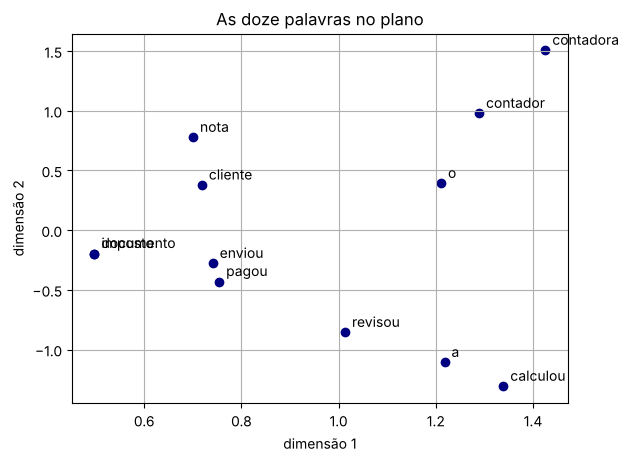

In [27]:
# Importa o módulo de gráficos do matplotlib com o apelido plt
import matplotlib.pyplot as plt

# Percorre cada palavra do vocabulário
for p in palavras_corpus:
    # Pega as duas coordenadas da palavra (desmonta o vetor em x e y)
    x, y = EMB[indice[p]]
    # Desenha um ponto azul-marinho ("navy") na posição da palavra
    plt.scatter(x, y, c="navy")
    # Escreve o nome da palavra um pouco à direita e acima do ponto
    plt.annotate(p, (x, y), textcoords="offset points", xytext=(5, 4))
# Nome do eixo horizontal
plt.xlabel("dimensão 1")
# Nome do eixo vertical
plt.ylabel("dimensão 2")
# Título do gráfico
plt.title("As doze palavras no plano")
# Liga a grade de fundo, que facilita ler as posições
plt.grid(True)
# Exibe o gráfico
plt.show()

Procure os vizinhos: verbos com verbos, pessoas com pessoas. Procure o que parece estranho e explique.

**SUA VEZ**

1. Acrescente ao corpus a frase "o cliente pagou a nota" e refaça PPMI e SVD. Os cossenos mudaram? Documento e imposto continuam idênticos?
2. Escreva, com suas palavras, por que o resultado com doze frases não pode ser tomado como o significado das palavras.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [28]:
# Espaço para os seus testes

### Exercício 6. Um modelo de linguagem feito de contagens
*Exemplo 6 do capítulo*

O modelo de bigramas olha só a palavra anterior. Basta contar, no corpus, o que costuma vir depois de cada palavra.

In [29]:
# Cada frase vira lista de tokens com os marcadores de início <s> e fim </s>
tokens = [["<s>"] + s.split() + ["</s>"] for s in corpus]

# Contador de pares (palavra, próxima palavra)
bigramas = Counter()
# Contador de quantas vezes cada palavra aparece como contexto (antes de outra)
contexto = Counter()
# Percorre cada frase já com os marcadores
for t in tokens:
    # Pares de vizinhos da frase
    for a, b in zip(t, t[1:]):
        # Conta o par
        bigramas[(a, b)] += 1
        # Conta que a palavra a serviu de contexto mais uma vez
        contexto[a] += 1

# Probabilidade de b vir depois de a: P(b | a)
def p_bi(a, b):
    # Contagem do par dividida pelo total de vezes que a foi contexto
    return bigramas[(a, b)] / contexto[a]

# Cabeçalho da tabela
print("contexto  próxima     contagem  total  probabilidade")
# Percorre alguns contextos escolhidos
for ctx in ["<s>", "o", "a", "cliente"]:
    # Pares que começam por ctx; lambda é uma função de uma linha que diz como ordenar
    # (mais frequente antes; nos empates, ordem alfabética)
    opcoes = sorted([(b, c) for (a, b), c in bigramas.items() if a == ctx], key=lambda x: (-x[1], x[0]))
    # Percorre as próximas palavras possíveis
    for b, c in opcoes:
        # Mostra contagem, total do contexto e a probabilidade (contagem dividida pelo total)
        print(f"{ctx:8s}  {b:10s} {c:8d} {contexto[ctx]:6d}  {c / contexto[ctx]:.4f}")

contexto  próxima     contagem  total  probabilidade
<s>       o                 7     12  0.5833
<s>       a                 5     12  0.4167
o         cliente           4     15  0.2667
o         documento         4     15  0.2667
o         imposto           4     15  0.2667
o         contador          3     15  0.2000
a         nota              4      9  0.4444
a         contadora         3      9  0.3333
a         cliente           2      9  0.2222
cliente   enviou            3      6  0.5000
cliente   pagou             2      6  0.3333
cliente   revisou           1      6  0.1667


As probabilidades de cada contexto somam 1. Depois de "cliente", o verbo "enviou" tem probabilidade 0.5: é o que o corpus mais mostrou. O modelo não entende nada: sabe só o que costuma vir depois do quê.

**SUA VEZ**

1. Quais são as probabilidades depois de "contadora"? Elas somam 1?
2. Acrescente ao corpus dez vezes a frase "o cliente pagou o imposto" e veja o que acontece com P(enviou | cliente).

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [30]:
# Espaço para os seus testes

### Exercício 7. A probabilidade de uma frase e a perplexidade
*Exemplo 7 do capítulo*

Multiplicando as probabilidades de cada passo, obtemos a probabilidade da frase. A perplexidade mede a surpresa média por palavra.

In [31]:
# Calcula a probabilidade e a perplexidade de uma frase; suavizar=False é um valor padrão
def avaliar(frase, suavizar=False):
    # Tokens da frase com os marcadores de início e fim
    t = ["<s>"] + frase.split() + ["</s>"]
    # Tamanho do vocabulário usado na suavização
    V = len(palavras_corpus) + 1          # palavras do corpus mais o marcador de fim
    # A probabilidade da frase começa em 1 e vai sendo multiplicada
    p = 1.0
    # Soma dos logaritmos, usada na perplexidade
    soma_log = 0.0
    # Percorre cada passo (palavra anterior, palavra seguinte)
    for a, b in zip(t, t[1:]):
        # Se pediram suavização...
        if suavizar:
            # ...Laplace: soma 1 a cada contagem e V ao total, para nenhum par ficar com zero
            q = (bigramas[(a, b)] + 1) / (contexto[a] + V)
        # Senão, usa a probabilidade simples das contagens
        else:
            # Probabilidade do bigrama
            q = p_bi(a, b)
        # Se algum passo é impossível (probabilidade zero)...
        if q == 0:
            # ...a frase toda é impossível; None indica que a perplexidade não existe
            return 0.0, None
        # Multiplica a probabilidade deste passo
        p = p * q
        # Acumula o logaritmo deste passo
        soma_log = soma_log + math.log(q)
    # Perplexidade: exponencial do negativo da média dos logs (a surpresa média por passo)
    perplexidade = math.exp(-soma_log / (len(t) - 1))
    # Devolve a probabilidade e a perplexidade
    return p, perplexidade

# Percorre três frases para avaliar
for frase in ["o cliente enviou o documento", "o cliente enviou a nota", "o contador pagou a nota"]:
    # Calcula P e perplexidade da frase
    p, pp = avaliar(frase)
    # {p:.6f} mostra a probabilidade com 6 casas, pois ela é pequena
    print(f"{frase:30s} P = {p:.6f}   perplexidade = {pp:.4f}")

# Linha em branco
print()
# Avalia uma frase com a ordem trocada
p, pp = avaliar("a nota enviou o cliente")
# Sem formatação numérica, pois pp é None (não dá para formatar None como número)
print(f"a nota enviou o cliente        P = {p}   perplexidade = {pp}")

o cliente enviou o documento   P = 0.010370   perplexidade = 2.1414
o cliente enviou a nota        P = 0.017284   perplexidade = 1.9666
o contador pagou a nota        P = 0.005761   perplexidade = 2.3618

a nota enviou o cliente        P = 0.0   perplexidade = None


A frase "a nota enviou o cliente" nunca apareceu: o par (nota, enviou) tem contagem zero e o modelo a considera impossível. A correção mais simples é a suavização de Laplace:

In [32]:
# Título
print("com suavização de Laplace:")
# Uma frase conhecida e uma que o modelo sem suavização achava impossível
for frase in ["o cliente enviou o documento", "a nota enviou o cliente"]:
    # Agora com suavizar=True
    p, pp = avaliar(frase, suavizar=True)
    # Mostra a probabilidade e a perplexidade
    print(f"{frase:30s} P = {p:.6f}   perplexidade = {pp:.4f}")

com suavização de Laplace:
o cliente enviou o documento   P = 0.000111   perplexidade = 4.5581
a nota enviou o cliente        P = 0.000005   perplexidade = 7.5682


A frase impossível agora tem probabilidade pequena, mas diferente de zero. E a frase que o modelo já conhecia perdeu um pouco de probabilidade: parte dela foi reservada para o que ainda não se viu.

**SUA VEZ**

1. Invente uma frase que o modelo considere muito provável e outra que considere impossível. Teste as duas.
2. Explique, com suas palavras, o que significa uma perplexidade de 2.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [33]:
# Espaço para os seus testes

### Exercício 8. O softmax e o botão da temperatura
*Exemplo 8 do capítulo*

O modelo calcula uma pontuação para cada palavra possível. O softmax transforma as pontuações em probabilidades, e a temperatura controla o quanto o modelo é decidido.

In [34]:
# Softmax com temperatura T: transforma pontuações em probabilidades
def softmax(pontuacoes, T=1.0):
    # math.exp aplica a exponencial a cada pontuação dividida pela temperatura
    e = [math.exp(z / T) for z in pontuacoes]
    # Soma das exponenciais
    soma = sum(e)
    # Divide pela soma para que as probabilidades fiquem entre 0 e 1 e somem 1
    return [v / soma for v in e]

# Entropia em bits: mede o quanto a distribuição é espalhada (incerta)
def entropia(p):
    # Soma de -x * log2(x); o "if x > 0" pula os zeros, pois log de 0 não existe
    return -sum(x * math.log2(x) for x in p if x > 0)

# As palavras candidatas
palavras_pont = ["enviou", "pagou", "revisou"]
# A pontuação que o modelo deu a cada palavra
pontuacoes = [2.0, 1.0, 0.1]

# Cabeçalho da tabela
print("temperatura   enviou   pagou  revisou   entropia (bits)")
# Testa três temperaturas
for T in (0.5, 1, 2):
    # Probabilidades com essa temperatura
    p = softmax(pontuacoes, T)
    # Mostra as três probabilidades e a entropia
    print(f"{T:11}   {p[0]:6.4f}  {p[1]:6.4f}  {p[2]:6.4f}   {entropia(p):10.4f}")

temperatura   enviou   pagou  revisou   entropia (bits)
        0.5   0.8638  0.1169  0.0193       0.6545
          1   0.6590  0.2424  0.0986       1.2216
          2   0.5017  0.3043  0.1940       1.4806


Com temperatura baixa, o modelo é decidido e previsível (entropia baixa). Com temperatura alta, é mais disperso. Nada foi reaprendido: só a escolha foi suavizada ou endurecida. Um gráfico ajuda a ver:

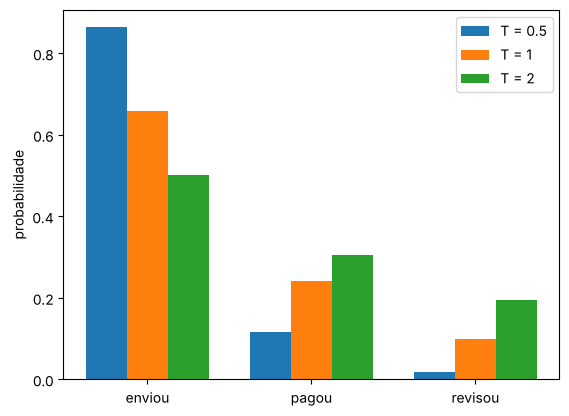

In [35]:
# Importa o matplotlib (já importado antes; repetir não causa problema)
import matplotlib.pyplot as plt

# Largura de cada barra
largura = 0.25
# Uma série de barras para cada temperatura; k vale 0, 1 e 2
for k, T in enumerate((0.5, 1, 2)):
    # Desloca as barras de cada temperatura para ficarem lado a lado
    posicoes = [i + (k - 1) * largura for i in range(3)]
    # Desenha as barras das probabilidades; label dá o nome que aparece na legenda
    plt.bar(posicoes, softmax(pontuacoes, T), largura, label=f"T = {T}")
# Coloca os nomes das palavras embaixo das posições 0, 1 e 2
plt.xticks(range(3), palavras_pont)
# Nome do eixo vertical
plt.ylabel("probabilidade")
# Mostra a legenda com as temperaturas
plt.legend()
# Exibe o gráfico
plt.show()

A mesma pontuação, três comportamentos.

**SUA VEZ**

1. Teste a temperatura 0.1 e a temperatura 10. O que acontece nos dois extremos?
2. Mude as pontuações para [1.0, 1.0, 1.0]. A temperatura ainda faz diferença? Por quê?

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [36]:
# Espaço para os seus testes

### Exercício 9. Escrever uma frase, palavra por palavra
*Exemplo 9 do capítulo*

Para gerar texto, o modelo escolhe uma palavra, acrescenta ao contexto e prevê a seguinte. Podemos escolher sempre a mais provável (gulosa) ou sortear.

In [37]:
# Geração gulosa: escolhe sempre a próxima palavra mais provável, até no máximo 14 palavras
def gulosa(maximo=14):
    # Lista das palavras geradas
    saida = []
    # Começa pelo marcador de início de frase
    atual = "<s>"
    # Repete no máximo "maximo" vezes
    for _ in range(maximo):
        # Lista (contagem, palavra) das que vêm depois de atual, da mais frequente para a menos
        opcoes = sorted([(c, b) for (a, b), c in bigramas.items() if a == atual], key=lambda x: (-x[0], x[1]))
        # Pega a palavra da primeira opção, a mais frequente
        proxima = opcoes[0][1]
        # Se a escolhida for o fim de frase...
        if proxima == "</s>":
            # ...break sai do laço
            break
        # Acrescenta a palavra à frase gerada
        saida.append(proxima)
        # A palavra escolhida vira o novo contexto
        atual = proxima
    # Junta as palavras em uma frase
    return " ".join(saida)

# Geração por sorteio, com semente para poder repetir o resultado
def sortear(semente, maximo=12):
    # Gerador de sorteios com a semente dada
    rng = random.Random(semente)
    # Lista das palavras geradas
    saida = []
    # Começa pelo marcador de início
    atual = "<s>"
    # Repete no máximo "maximo" vezes
    for _ in range(maximo):
        # Lista (palavra, contagem) das que vêm depois de atual, em ordem alfabética
        opcoes = sorted([(b, c) for (a, b), c in bigramas.items() if a == atual])
        # Sorteia uma palavra usando as contagens como pesos
        proxima = rng.choices([b for b, c in opcoes], weights=[c for b, c in opcoes])[0]
        # Se saiu o fim de frase...
        if proxima == "</s>":
            # ...encerra a geração
            break
        # Acrescenta a palavra sorteada
        saida.append(proxima)
        # Ela vira o novo contexto: o modelo só enxerga a palavra anterior
        atual = proxima
    # Devolve a frase gerada
    return " ".join(saida)

# A frase gulosa é sempre a mesma
print("gulosa:", gulosa())
# Linha em branco
print()
# Testa as sementes de 0 a 4
for semente in range(5):
    # Cada semente gera uma frase sorteada diferente
    print(f"semente {semente}: {sortear(semente)}")

gulosa: o cliente enviou a nota

semente 0: o imposto
semente 1: a nota
semente 2: o imposto
semente 3: a contadora enviou o documento
semente 4: a cliente enviou a cliente enviou o imposto


A escolha gulosa produz sempre a mesma frase. O sorteio produz variedade, inclusive frases que nunca apareceram no corpus. Como o modelo só enxerga a palavra anterior, ele não lembra que já falou de um cliente. É por isso que os modelos modernos olham centenas ou milhares de palavras para trás.

**SUA VEZ**

1. Rode o sortear com as sementes de 10 a 20 e anote as frases mais estranhas.
2. Explique por que a mesma pergunta, em um assistente de conversa, pode receber respostas diferentes.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [38]:
# Espaço para os seus testes

### Exercício 10. A resposta mais frequente e a resposta certa
*Exemplo 10 do capítulo*

Fluência não é verdade. Vamos ver como um modelo pode dar, com confiança, a resposta errada, e como mais contexto ajuda.

In [39]:
# Pequeno corpus com datas de vencimento de impostos
frases = ["o imposto da folha vence dia 10",
          "o imposto do cliente vence dia 10",
          "o imposto da nota vence dia 10",
          "o imposto do simples vence dia 20"]

# Conta quais palavras vêm logo depois de um contexto de uma ou mais palavras
def proximas(contexto_texto):
    # Corta o contexto em palavras
    ctx = contexto_texto.split()
    # Tamanho do contexto (quantas palavras o modelo olha para trás)
    n = len(ctx)
    # Contador das palavras seguintes
    c = Counter()
    # Percorre cada frase
    for f in frases:
        # Corta a frase em palavras
        t = f.split()
        # Percorre as posições em que cabe o contexto seguido de mais uma palavra
        for i in range(len(t) - n):
            # Se o trecho t[i:i + n] (uma fatia) é igual ao contexto...
            if t[i:i + n] == ctx:
                # ...conta a palavra que vem logo depois
                c[t[i + n]] += 1
    # Devolve as contagens
    return c

# Testa contextos cada vez mais longos
for ctx in ["dia", "vence dia", "simples vence dia"]:
    # Contagens das próximas palavras para esse contexto
    c = proximas(ctx)
    # Total de ocorrências do contexto
    total = sum(c.values())
    # Monta o texto "palavra: probabilidade" para cada opção, separado por vírgulas
    detalhe = ", ".join(f"{p}: {v / total:.2f}" for p, v in sorted(c.items()))
    # \" coloca aspas dentro do texto sem encerrá-lo
    print(f"contexto \"{ctx}\" -> {detalhe}")

contexto "dia" -> 10: 0.75, 20: 0.25
contexto "vence dia" -> 10: 0.75, 20: 0.25
contexto "simples vence dia" -> 20: 1.00


Pergunta: "o imposto do simples vence dia ___". O modelo que olha só a palavra "dia" responde 10 com 75% de confiança, e está errado: no corpus, o simples vence dia 20. O modelo que olha as três últimas palavras acerta. Mas ele acertou porque o corpus continha a informação, uma única vez. Fluência e confiança não são verdade: a verificação continua sendo humana.

**SUA VEZ**

1. Acrescente uma quinta frase "o imposto do mei vence dia 20" e refaça. O que muda para o contexto "dia"?
2. Escreva um parágrafo sobre o que o Exemplo 10 ensina a quem usa um assistente de IA no trabalho.

*Escreva aqui as suas respostas e faça os testes na célula de código abaixo.*

In [40]:
# Espaço para os seus testes

## Parte 3. A mesma coisa em poucas linhas (scikit-learn)

### D1. Contagem e cosseno com a biblioteca
*compare com o Exercício 2*

In [41]:
# Importa do scikit-learn os vetorizadores de contagem e de TF-IDF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
# Importa a função pronta da semelhança do cosseno
from sklearn.metrics.pairwise import cosine_similarity

# Vetorizador de contagem usando o mesmo vocabulário do Exercício 2
cv = CountVectorizer(vocabulary=vocab_lista)
# Transforma os chamados em uma tabela de contagens (uma linha por chamado)
X = cv.transform(docs)
# Transforma a consulta (dentro de uma lista, pois a função espera vários textos)
q = cv.transform([consulta])

# Cosseno da consulta com cada chamado, calculado pela biblioteca
print("cosseno com contagem (scikit-learn):", cosine_similarity(q, X).round(4))
# O mesmo cálculo com as funções feitas à mão, para comparar
print("cosseno na mão:                     ", np.array([cosseno(contar(consulta), contar(d)) for d in docs]).round(4))

cosseno com contagem (scikit-learn): [[0.7071 0.6325 0.     0.    ]]
cosseno na mão:                      [0.7071 0.6325 0.     0.    ]


Os dois resultados coincidem até a quarta casa decimal. O CountVectorizer corta o texto em palavras, monta o vocabulário e conta.

### D2. TF-IDF com a biblioteca
*compare com o Exercício 3*

In [42]:
# TfidfVectorizer com o mesmo vocabulário; .fit(docs) calcula o idf a partir dos chamados
tv = TfidfVectorizer(vocabulary=vocab_lista).fit(docs)
# Cosseno TF-IDF da consulta com cada chamado, pela biblioteca
print("cosseno TF-IDF (scikit-learn):", cosine_similarity(tv.transform([consulta]), tv.transform(docs)).round(4))
# O mesmo cálculo feito à mão no Exercício 3
print("cosseno TF-IDF na mão:        ", np.array([tfidf(consulta) @ tfidf(d) for d in docs]).round(4))
# Linha em branco
print()
# tv.idf_ guarda os pesos idf; .index("de") acha a posição de "de" no vocabulário
print("idf da biblioteca para \"de\":  ", round(tv.idf_[vocab_lista.index("de")], 4))
# O idf de "de" calculado à mão, para comparar
print("idf na mão para \"de\":         ", round(idf["de"], 4))

cosseno TF-IDF (scikit-learn): [[0.6588 0.6164 0.     0.    ]]
cosseno TF-IDF na mão:         [0.6588 0.6164 0.     0.    ]

idf da biblioteca para "de":   1.2231
idf na mão para "de":          1.2231


O scikit-learn usa exatamente a versão suavizada do idf que calculamos à mão, e normaliza cada vetor para ter comprimento 1.

### D3. SVD com a biblioteca
*compare com o Exercício 5*

In [43]:
# Importa a SVD truncada do scikit-learn, que calcula só as primeiras dimensões
from sklearn.decomposition import TruncatedSVD

# Pede 2 dimensões; random_state=0 fixa a semente para o resultado se repetir
svd = TruncatedSVD(n_components=2, algorithm="arpack", random_state=0).fit(PPMI)
# Posição de cada palavra nas 2 dimensões
EMB_sk = svd.transform(PPMI)

# Compara alguns pares de palavras
for a, b in [("cliente", "contador"), ("enviou", "pagou"), ("documento", "nota"), ("documento", "imposto")]:
    # Cosseno entre os vetores da biblioteca
    c_sk = cosseno(EMB_sk[indice[a]], EMB_sk[indice[b]])
    # Mostra lado a lado o cosseno feito à mão e o da biblioteca
    print(f"{a:10s} e {b:10s} cosseno na mão = {sim(a, b):6.3f}   com a biblioteca = {c_sk:6.3f}")

cliente    e contador   cosseno na mão =  0.986   com a biblioteca =  0.986
enviou     e pagou      cosseno na mão =  0.987   com a biblioteca =  0.987
documento  e nota       cosseno na mão =  0.351   com a biblioteca =  0.351
documento  e imposto    cosseno na mão =  1.000   com a biblioteca =  1.000


Os cossenos coincidem, mesmo que os sinais de cada coluna possam ser diferentes: a semelhança entre palavras não depende do sinal.

### D4. Bigramas com a biblioteca
*compare com o Exercício 6*

In [44]:
# Conta pares de palavras (ngram_range=(2, 2)); o token_pattern aceita palavras de uma letra
cv2 = CountVectorizer(ngram_range=(2, 2), token_pattern=r"\b\w+\b")
# Aprende os pares do corpus e monta a tabela frase x par
M2 = cv2.fit_transform(corpus)
# Soma a tabela por coluna (total de cada par) e monta o dicionário par: contagem
contagens = dict(zip(cv2.get_feature_names_out(), np.asarray(M2.sum(axis=0)).ravel()))

# Compara alguns pares
for par in ["o cliente", "o contador", "o documento", "cliente enviou", "cliente pagou"]:
    # tuple(par.split()) transforma "o cliente" em ("o", "cliente"), o formato do Counter
    print(f"{par:16s} biblioteca = {int(contagens[par])}   na mão = {bigramas[tuple(par.split())]}")

o cliente        biblioteca = 4   na mão = 4
o contador       biblioteca = 3   na mão = 3
o documento      biblioteca = 4   na mão = 4
cliente enviou   biblioteca = 3   na mão = 3
cliente pagou    biblioteca = 2   na mão = 2


A biblioteca conta os pares sem os marcadores de início e fim de frase, que nós acrescentamos. Para os pares do meio da frase, a contagem é idêntica. O CountVectorizer com ngram_range é a forma padrão de contar pares e trios de palavras.

### Desafio final, sem código pronto
A biblioteca `tiktoken` reproduz o tokenizador de alguns modelos. Instale com `!pip install tiktoken` e descubra, lendo a documentação, como contar os tokens de um texto.

1. Escolha cinco frases em português sobre o trabalho da ServiPro e traduza cada uma para o inglês. Conte as palavras e os tokens de cada frase nos dois idiomas.
2. Calcule, para cada idioma, a razão entre tokens e palavras.
3. Em uma célula de texto, escreva o que isso significa para quem paga por tokens e por que o resultado vale para o tokenizador testado, e não para todos.

In [45]:
# Espaço para os seus testes

---
**Entrega:** *Ambiente de execução > Reiniciar sessão e executar tudo*, depois *Compartilhar > qualquer pessoa com o link pode visualizar*, e cole o link no espaço indicado pelo professor.